# Inflación interanual en Chile (IPC)




### 1. La serie corresponde a la variación del Índice de Precios al Consumidor (IPC) en 12 meses, obtenida de la Base de Datos Estadísticos del Banco Central de Chile.

**Características de la serie:**

Frecuencia: Mensual.

Unidad de medida: Porcentaje (%), ya que representa la variación interanual del IPC y no el nivel del índice.

Período disponible: Enero de 2011 a agosto de 2026, con 188 observaciones mensuales.

## 1. Paquetes

In [34]:
# Colab (R) ya trae tidyverse; solo instala lo que falte
paquetes <- c("readxl", "dplyr", "ggplot2", "scales", "tidyr")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(readxl); library(dplyr); library(ggplot2); library(scales); library(tidyr)
})

## 2. Lectura y limpieza de datos
La hoja `Cuadro` trae el título en la fila 1 y los encabezados en la fila 3, por eso se saltan 2 filas.

In [35]:
archivo <- list.files(c("/content", "."), pattern = "\\.xlsx$", full.names = TRUE)[1]
if (is.na(archivo)) stop("No encontré el .xlsx. Súbelo desde el panel de archivos (ícono de carpeta).")
cat("Leyendo:", archivo, "\n")

raw <- read_excel(archivo, sheet = "Cuadro", skip = 2)

df <- raw |>
  select(fecha = 1, tasa = 2) |>
  mutate(fecha = as.Date(fecha), tasa = as.numeric(tasa)) |>
  filter(!is.na(fecha), !is.na(tasa)) |>
  arrange(fecha) |>
  mutate(
    anio      = as.integer(format(fecha, "%Y")),
    mes       = as.integer(format(fecha, "%m")),
    media_12m = as.numeric(stats::filter(tasa, rep(1/12, 12), sides = 1)),  # promedio móvil 12 meses
    var_12m   = tasa - lag(tasa, 12)                                         # variación en pp vs. año anterior
  )

cat("Observaciones:", nrow(df), "\n")
summary(df$tasa)
tail(df)

Leyendo: ./EI_PREC_VAR (Chile).xlsx 
Observaciones: 188 


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.900   2.700   3.550   4.198   4.600  14.100 

fecha,tasa,anio,mes,media_12m,var_12m
<date>,<dbl>,<int>,<int>,<dbl>,<dbl>
2026-03-01,2.8,2026,3,3.666667,-2.1
2026-04-01,4.0,2026,4,3.625000,-0.5
2026-05-01,3.9,2026,5,3.583333,-0.5
2026-06-01,4.3,2026,6,3.600000,0.2
2026-07-01,3.5,2026,7,3.533333,-0.8
2026-08-01,4.1,2026,8,3.541667,0.1


## 3. Estilo común para los gráficos

In [36]:
# Crea un vector con las abreviaturas de los 12 meses en español
meses_es  <- c("Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic")
# Crea una función que convierte una fecha en una etiqueta tipo "Ago 2026"
etq_fecha <- function(x) paste(meses_es[as.integer(format(x, "%m"))], format(x, "%Y"))
# Crea una función que formatea números
num_es    <- function(x) number(x, accuracy = 0.1, decimal.mark = ",")

col_principal <- "#1F4E79"   # azul
col_acento    <- "#E07B39"   # naranjo

# estilo visual común
tema <- theme_minimal(base_size = 13) +
  theme(
    plot.title         = element_text(face = "bold", size = 20, colour = "#1A1A1A"),
    plot.subtitle      = element_text(colour = "#555555", margin = margin(b = 12)),
    plot.caption       = element_text(colour = "#888888", size = 9, hjust = 0),
    plot.title.position = "plot", plot.caption.position = "plot",
    panel.grid.minor   = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = "#E5E5E5"),
    legend.position    = "top", legend.justification = "left",
    plot.background    = element_rect(fill = "white", colour = NA),
    plot.margin        = margin(15, 20, 10, 15)
  )

fuente <- "Fuente: Banco Central de Chile, Base de Datos Estadísticos. Serie EI_PREC_VAR (Chile): variación del IPC en 12 meses (%), frecuencia mensual."

## 4. Evolución del Índice de Precios al Consumidor (IPC)
Serie mensual, promedio móvil de 12 meses, período de pandemia sombreado y marcas en el máximo, el mínimo y el último dato.

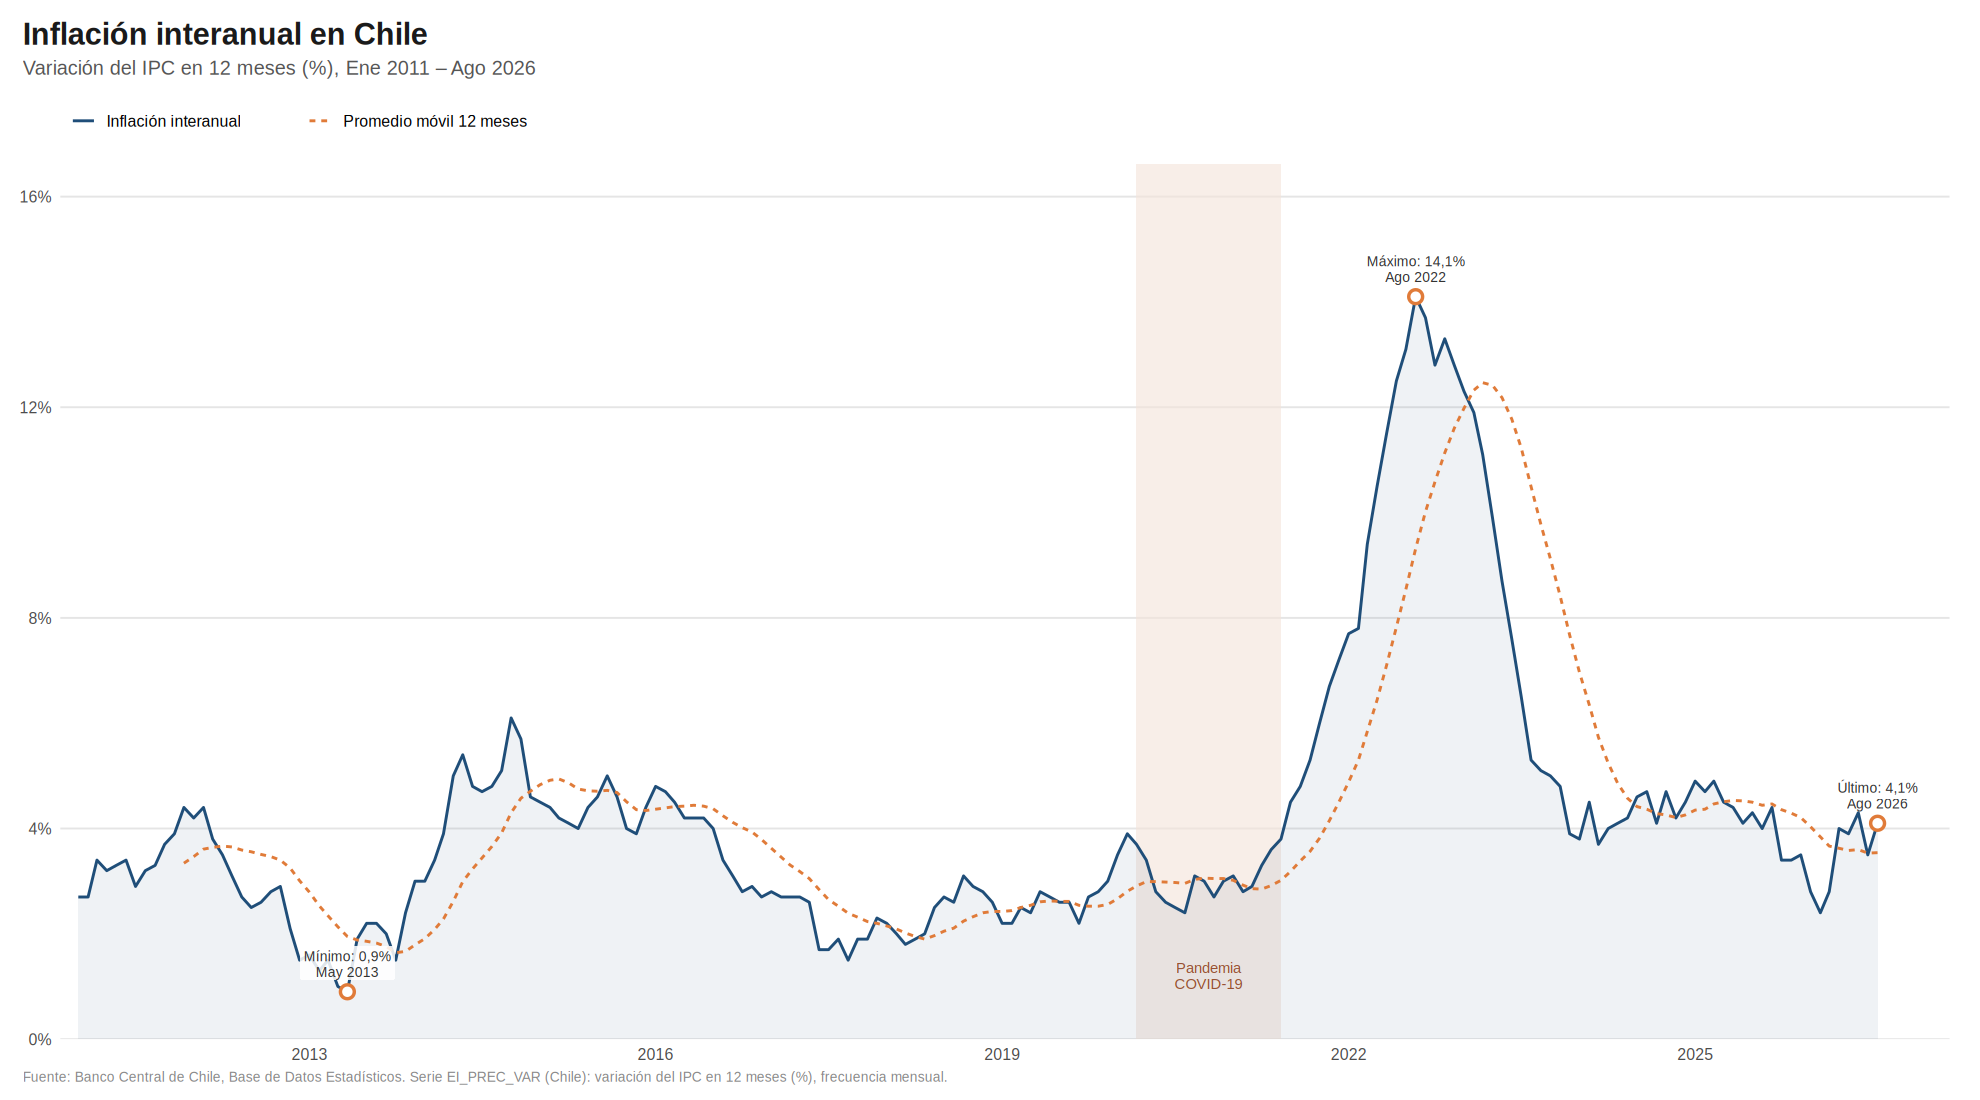

In [37]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 110)

# arma una pequeña tabla llamada hitos con los tres puntos que se destacan en el primer gráfico: el máximo, el mínimo y el último dato.
hitos <- bind_rows(
  df |> slice_max(tasa, n = 1, with_ties = FALSE) |> mutate(txt = paste0("Máximo: ", num_es(tasa), "%\n", etq_fecha(fecha))),
  df |> slice_min(tasa, n = 1, with_ties = FALSE) |> mutate(txt = paste0("Mínimo: ", num_es(tasa), "%\n", etq_fecha(fecha))),
  df |> slice_tail(n = 1)      |> mutate(txt = paste0("Último: ", num_es(tasa), "%\n", etq_fecha(fecha)))
)

# construye el gráfico (la serie de tiempo) y lo guarda como g1
g1 <- ggplot(df, aes(fecha)) +
  annotate("rect", xmin = as.Date("2020-03-01"), xmax = as.Date("2021-06-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = .6) +
  annotate("text", x = as.Date("2020-10-15"), y = 1.2, label = "Pandemia\nCOVID-19",
           size = 3.4, colour = "#A0522D", lineheight = .9) +
  geom_area(aes(y = tasa), fill = col_principal, alpha = .07) +
  geom_line(aes(y = tasa, colour = "Inflación interanual"), linewidth = .9) +
  geom_line(aes(y = media_12m, colour = "Promedio móvil 12 meses"),
            linewidth = .9, linetype = "22", na.rm = TRUE) +
  geom_point(data = hitos, aes(y = tasa), size = 3.2, colour = col_acento,
             fill = "white", shape = 21, stroke = 1.6) +
  geom_label(data = hitos, aes(y = tasa, label = txt), size = 3.2, vjust = -0.35,
             linewidth = 0, fill = alpha("white", .85), colour = "#333333", lineheight = .95) +
  scale_colour_manual(NULL, values = c("Inflación interanual" = col_principal,
                                       "Promedio móvil 12 meses" = col_acento)) +
  scale_x_date(date_breaks = "3 years", date_labels = "%Y",
               expand = expansion(mult = c(.01, .04))) +
  scale_y_continuous(labels = label_number(accuracy = 1, suffix = "%"),
                     limits = c(0, max(df$tasa) + 2.2), expand = expansion(mult = c(0, .02))) +
  labs(title = "Inflación interanual en Chile",
       subtitle = paste0("Variación del IPC en 12 meses (%), ",
                         etq_fecha(min(df$fecha)), " – ", etq_fecha(max(df$fecha))),
       x = NULL, y = NULL, caption = fuente) +
  tema

g1

El gráfico muestra la evolución de la inflación interanual en Chile entre enero de 2011 y agosto de 2026, medida como la variación porcentual del Índice de Precios al Consumidor (IPC) respecto del mismo mes del año anterior.

Durante gran parte del período, la inflación presentó fluctuaciones moderadas. Sin embargo, a partir de 2021 experimentó un fuerte aumento, alcanzando un máximo de 14,1% en agosto de 2022. Posteriormente, comenzó a disminuir, mostrando una importante desaceleración durante 2023. En agosto de 2026, la inflación interanual se situó en 4,1%.

Para analizar su evolución, se utiliza un promedio móvil de 12 meses que permite suavizar las fluctuaciones y observar con mayor claridad la tendencia general de la inflación.





## 5. Mapa de calor por año y mes
Permite ver de un vistazo los años altos y bajos y el patrón estacional.

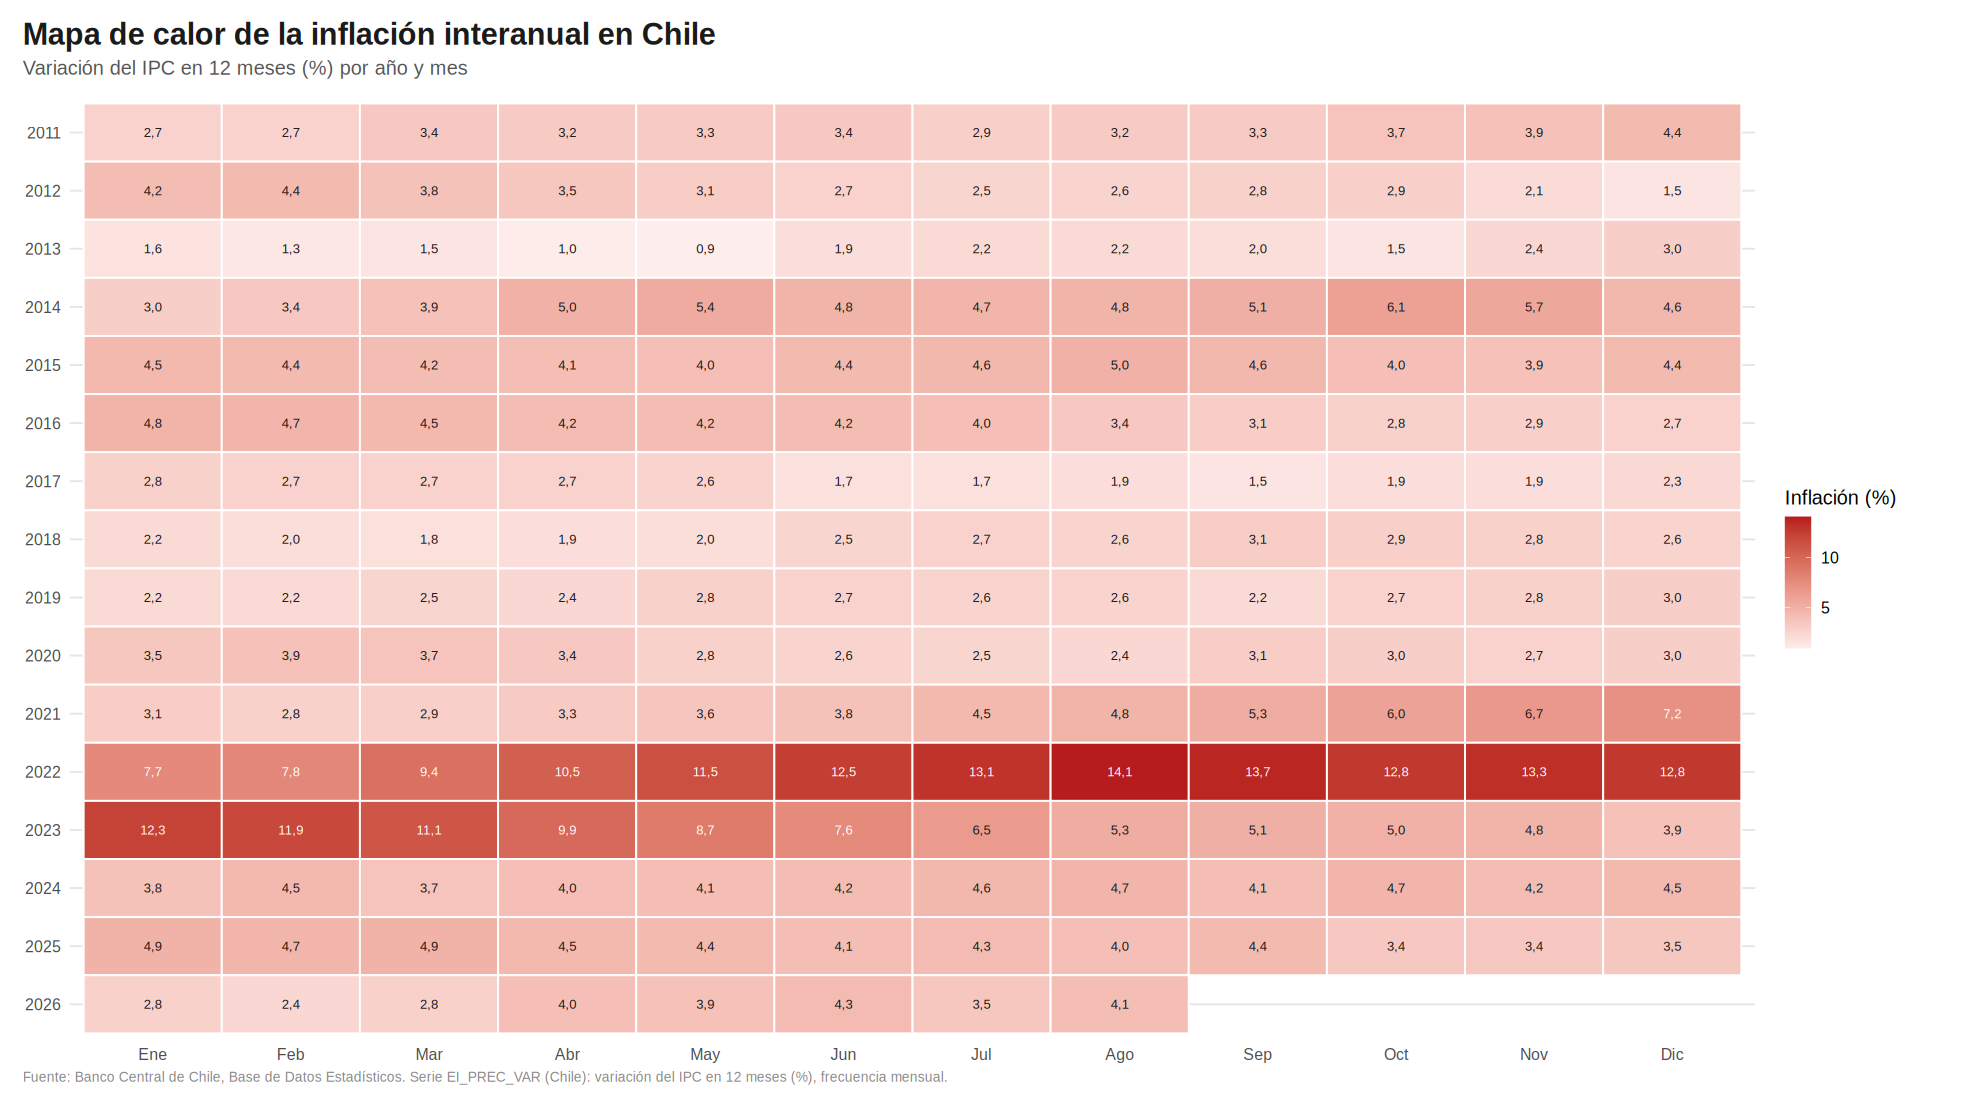

In [38]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10)

# construye el mapa de calor y lo guarda como g2
g2 <- ggplot(df, aes(factor(mes, levels = 1:12, labels = meses_es),
                     factor(anio, levels = rev(sort(unique(anio)))),
                     fill = tasa)) +
  geom_tile(colour = "white", linewidth = .6) +
  geom_text(aes(label = num_es(tasa), colour = tasa > 7), size = 3, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#1A1A1A")) +
  scale_fill_gradient(low = "#FDEDEC", high = "#B71C1C", name = "Inflación (%)") +
  labs(title = "Mapa de calor de la inflación interanual en Chile",
       subtitle = "Variación del IPC en 12 meses (%) por año y mes", x = NULL, y = NULL, caption = fuente) +
  tema + theme(panel.grid = element_blank(), legend.position = "right")

g2

El mapa de calor muestra la evolución de la inflación interanual en Chile entre enero de 2011 y agosto de 2026. Los colores más claros representan menores tasas de inflación, mientras que los tonos más oscuros indican niveles más elevados.

Se observa un fuerte aumento de la inflación durante 2021 y 2022, alcanzando un máximo de 14,1% en agosto de 2022. Posteriormente, la inflación comenzó a disminuir durante 2023, manteniéndose en niveles considerablemente inferiores en los años siguientes. En contraste, el mínimo del período se registró en mayo de 2013, con una inflación de 0,9%.

En agosto de 2026, la inflación interanual alcanzó un 4,1%. El mapa permite comparar los niveles de inflación entre distintos meses y años, facilitando la identificación de períodos de mayor y menor inflación.

## 6. Variación en 12 meses
Cuántos puntos porcentuales subió o bajó la tasa respecto del mismo mes del año anterior.

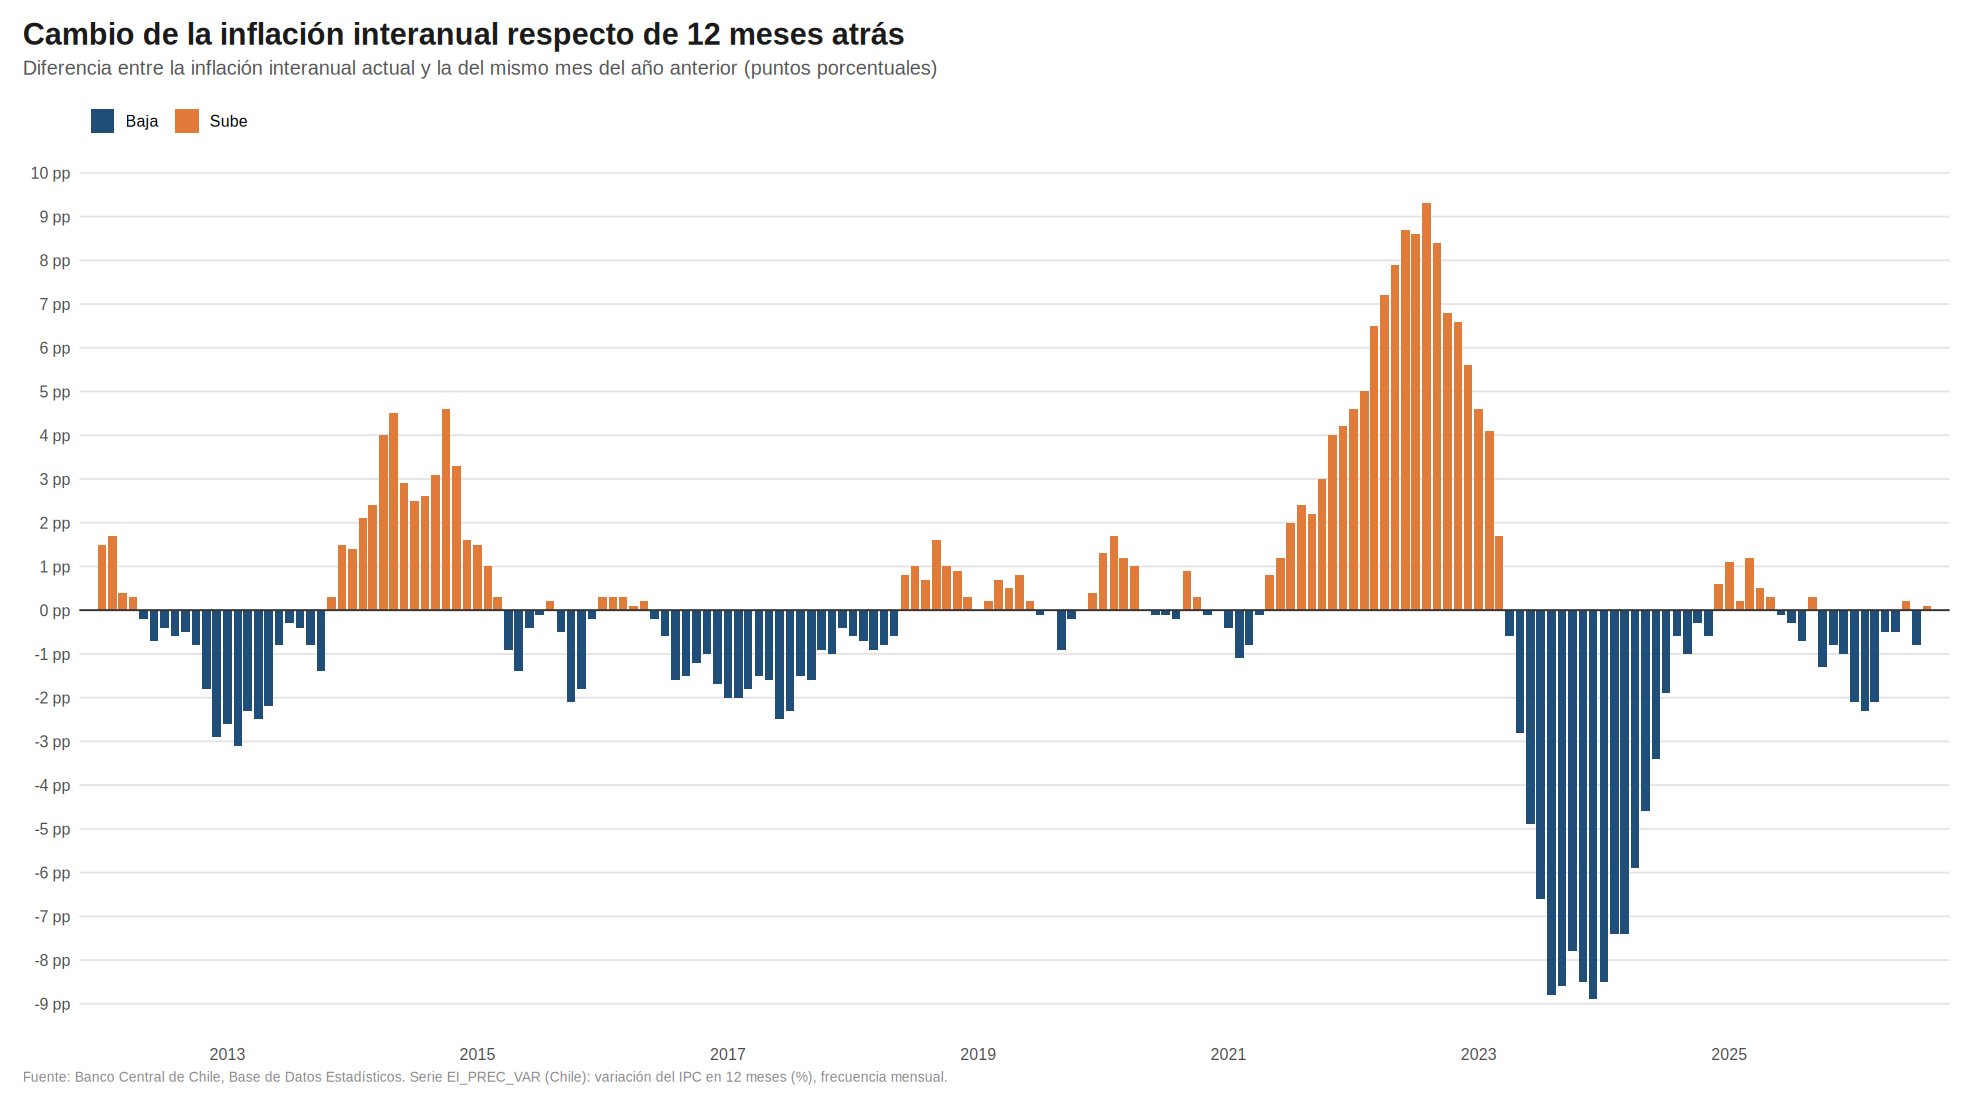

In [39]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10)

# construye el gráfico de barras de la variación en 12 meses y lo guarda como g3
g3 <- df |>
  filter(!is.na(var_12m)) |>
  ggplot(aes(fecha, var_12m, fill = var_12m > 0)) +
  geom_col(width = 25) +
  geom_hline(yintercept = 0, colour = "#333333") +
  scale_fill_manual(NULL, values = c(`TRUE` = col_acento, `FALSE` = col_principal),
                    labels = c(`TRUE` = "Sube", `FALSE` = "Baja")) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y", expand = expansion(mult = c(0.01, 0.01))) +
  scale_y_continuous(breaks = breaks_width(1), labels = label_number(accuracy = 1, suffix = " pp")) +
  labs(title = "Cambio de la inflación interanual respecto de 12 meses atrás",
       subtitle = "Diferencia entre la inflación interanual actual y la del mismo mes del año anterior (puntos porcentuales)",
       x = NULL, y = NULL, caption = fuente) +
  tema

g3

El gráfico muestra el cambio de la inflación interanual en Chile respecto del mismo mes del año anterior, expresado en puntos porcentuales. Las barras naranjas representan aumentos de la tasa de inflación, mientras que las azules indican disminuciones.

Se observa un fuerte incremento de la inflación durante 2021 y 2022, con diferencias positivas superiores a 9 puntos porcentuales. Posteriormente, durante 2023 y 2024, se registraron diferencias negativas cercanas a 9 puntos porcentuales, lo que refleja una importante desaceleración de la inflación.

Hacia el final del período, los cambios se moderan considerablemente en comparación con los máximos y mínimos anteriores.

Dado que la serie original ya corresponde a la variación porcentual del IPC en 12 meses, se calcula la diferencia entre tasas y no una nueva variación porcentual. Por esta razón, los resultados se expresan en puntos porcentuales (pp.).

# Interpretación

La serie analizada muestra la evolución de la inflación interanual en Chile entre enero de 2011 y agosto de 2026. El dato más reciente corresponde a agosto de 2026, cuando la inflación alcanzó un 4,1%, valor ligeramente inferior al promedio del período, de aproximadamente 4,2%. Esto indica que la inflación actual se encuentra cercana al promedio de la muestra, aunque todavía por encima de la meta de inflación del 3% del Banco Central de Chile.

El valor máximo se registró en agosto de 2022, con un 14,1%, mientras que el mínimo ocurrió en mayo de 2013, con un 0,9%. El fuerte aumento de 2022 puede relacionarse con los efectos económicos posteriores a la pandemia, el incremento de la liquidez y del consumo interno, los problemas en las cadenas de suministro y el alza internacional de los precios de la energía y los alimentos. Por su parte, la baja inflación de 2013 puede asociarse con un contexto de menores presiones inflacionarias.

El mapa de calor permite identificar los períodos de mayor y menor inflación. Sin embargo, no se observa un patrón estacional consistente que se repita en determinados meses todos los años. Los valores más elevados se concentran principalmente entre 2021 y comienzos de 2023, reflejando un fenómeno inflacionario prolongado más que un comportamiento estacional. Además, al tratarse de variaciones interanuales del IPC, esta representación no permite identificar directamente la estacionalidad de las variaciones mensuales de precios.

Finalmente, el gráfico de variación en 12 meses muestra un fuerte aumento de la inflación durante 2021 y 2022, seguido de una marcada desaceleración durante 2023 y 2024. Hacia el final del período, las diferencias respecto del mismo mes del año anterior son considerablemente menores, lo que sugiere una estabilización relativa de la inflación. En agosto de 2026, la tasa aumentó 0,1 puntos porcentuales respecto de agosto de 2025, indicando un cambio interanual reducido.

## 7. Guardar los gráficos en PNG
Quedan en el panel de archivos; clic derecho → Descargar.

In [40]:
ggsave("inflacion_serie.png",       g1, width = 12, height = 6.5, dpi = 300)
ggsave("inflacion_mapa_calor.png",  g2, width = 11, height = 8,   dpi = 300)
ggsave("inflacion_variacion12m.png", g3, width = 12, height = 5.5, dpi = 300)
list.files(pattern = "\\.png$")

[1] "desocupacion_mapa_calor.png"   "desocupacion_serie.png"       
[3] "desocupacion_variacion12m.png" "inflacion_mapa_calor.png"     
[5] "inflacion_serie.png"           "inflacion_variacion12m.png"